# 04 · Predictive model

**Goal:** predict a batch's shelf-life stability (months) **at production time**, from its sensor readings, with a **confidence interval** and an **explanation**, so the Quality team does not have to wait months for the lab.

**Protocol, fixed before any model was trained:**
- one row = one batch; inputs = the 7 sensors, plus a variant **without density** (density is only known after the separation step); plant, reactor and date are not inputs;
- **time split** (primary): train on April 1 – June 8, test on June 9 – 29; the last 10 training days calibrate the intervals. A random 75/25 split is shown for comparison;
- every fitted step (imputation, scaling, interval width) is learned on training data only;
- records with no sensor data are excluded from training and handled separately.

**Candidates:** training mean, reactor mean, linear regression, additive spline model, random forest, LightGBM.
**Selection rule:** the simplest model whose test MAE is within 0.05 months of the best, and whose MAE on Technical-grade batches is within 0.10 months of the best.

| Step | Content |
|---|---|
| 4.1 | Data, splits, metrics, baselines |
| 4.2 | Candidate models, with and without density |
| 4.3 | Selection and error analysis |
| 4.4 | Prediction intervals (conformal) and their coverage |
| 4.5 | Explanations, saved model, model card |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import importlib
import numpy as np
import pandas as pd
from fragrance import config, model, plots

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

df = pd.read_parquet(config.CLEAN_PARQUET)   # produced by notebooks/02_cleaning.ipynb
empty = df["all_sensors_missing"]
data = df[~empty].reset_index(drop=True)
y = data[config.TARGET]
print(f"{len(df):,} batches; {empty.sum():,} without sensor data set aside; {len(data):,} used for modelling")

259,200 batches; 5,344 without sensor data set aside; 253,856 used for modelling


## 4.1 · Splits, metrics and baselines
**Metrics:**
- **MAE** (mean absolute error), in months: on average, how far the prediction is from the lab result;
- **MAE on Technical batches**: the same, only for batches whose true stability is below 20 months, the ones the business most needs to catch;
- RMSE and R² for the technical audience.

**Baselines** set the bar any model must clear: predicting the training average for every batch, and predicting the average of the batch's reactor (what a plant could do without any sensor).

In [2]:
ts = model.time_split(data)
rs = model.random_split(data)
summary = pd.DataFrame({
    name: {"batches": int(m.sum()), "from": data.loc[m, "event_time"].min().date(), "to": data.loc[m, "event_time"].max().date(),
           "share Technical": (y[m] < model.LOW_THRESHOLD).mean()}
    for name, m in {"train (fit)": ts["fit"], "train (calibration)": ts["calib"], "test": ts["test"]}.items()
}).T
summary

,batches,from,to,share Technical
train (fit),166026,2023-04-01,2023-05-29,0.253237
train (calibration),28358,2023-05-30,2023-06-08,0.29318
test,59472,2023-06-09,2023-06-29,0.293651


The split as a timeline: the model is fitted on the past, the intervals are calibrated on the next ten days, and the last three weeks are kept for the final test.

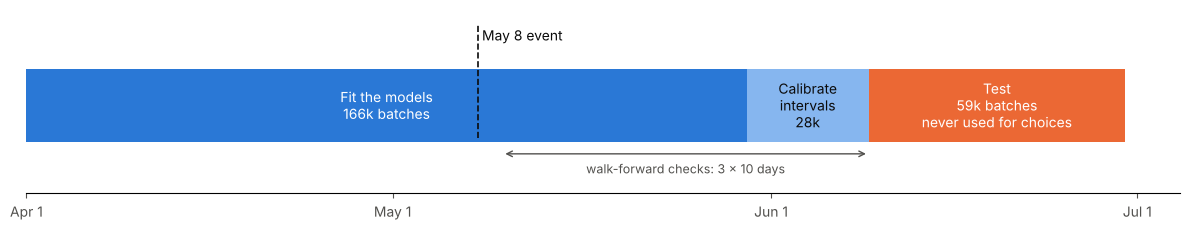

In [3]:
day = pd.Timedelta(days=1)
periods = pd.DataFrame([
    {"start": data.loc[ts[k], "event_time"].min().normalize(), "end": data.loc[ts[k], "event_time"].max().normalize() + day,
     "label": label.format(n=ts[k].sum() / 1000), "color": color}
    for k, label, color in [("fit", "Fit the models\n{n:.0f}k batches", plots.CATEGORICAL[0]),
                            ("calib", "Calibrate\nintervals\n{n:.0f}k", "#86b6ef"),
                            ("test", "Test\n{n:.0f}k batches\nnever used for choices", plots.CATEGORICAL[1])]])
plots.time_split_diagram(periods, pd.Timestamp("2023-05-08"), (pd.Timestamp("2023-05-10"), pd.Timestamp("2023-06-09")),
                         filename="model_time_split.png");

In [4]:
def evaluate(estimator, split, features):
    """Fit on the split's training rows, return test metrics."""
    tr, te = split["train"], split["test"]
    est = estimator.fit(data.loc[tr, features], y[tr])
    return model.regression_metrics(y[te], est.predict(data.loc[te, features]))

baselines = {
    "training mean": (model.MeanBaseline(), ["reactor"]),
    "reactor mean": (model.GroupMeanBaseline("reactor"), ["reactor"]),
}
rows = {}
for name, (est, feats) in baselines.items():
    rows[(name, "time split")] = evaluate(est, ts, feats)
    rows[(name, "random split")] = evaluate(est, rs, feats)
baseline_table = pd.DataFrame(rows).T
baseline_table.round(3)

MAE  MAE_technical   RMSE     R2        n
training mean time split    1.738          2.431  2.093 -0.005  59472.0
              random split  1.691          2.315  2.054 -0.000  63582.0
reactor mean  time split    1.626          2.127  1.948  0.130  59472.0
              random split  1.624          2.055  1.976  0.074  63582.0

## 4.1 · Conclusions
- **Splits:** 166,026 batches to fit the models (April 1 – May 29), 28,358 to calibrate the intervals (May 30 – June 8), 59,472 to test (June 9 – 29). The test period has more Technical batches (29% vs 25%), partly because the May 8 event weighs more in June: it is a harder, realistic test.
- **The bar to beat:** predicting each reactor's average gives MAE **1.63 months** and R² 0.13 on the time split. Predicting the overall average gives MAE 1.74 and R² ≈ 0. Any useful model must be clearly better than "the reactor's usual level".
- Time and random splits give similar baselines; the differences between them will matter more for flexible models.

## 4.2 · Candidate models
Each candidate is fitted on the training period and scored on the test period, with all 7 sensors and without density. Fitted with fixed, reasonable settings and no tuning, so the comparison is like-for-like:
- **linear:** ordinary least squares on the phase-3 features (distance of pH and pressure from their best value, learned on the training data), missing values filled with the training median plus a "was missing" indicator;
- **splines:** an additive model: one smooth curve per sensor, summed (GAM-like);
- **random forest:** many deep trees on bootstrap samples, averaged;
- **lightgbm:** gradient boosting, trees built one after another to correct each other's errors; handles missing values itself.

In [5]:
import time

feature_sets = {"7 sensors": model.FEATURES, "without density": model.FEATURES_NO_DENSITY}
results, test_preds, fitted = {}, {}, {}
for fs_name, feats in feature_sets.items():
    for split_name, split in {"time split": ts, "random split": rs}.items():
        for name, est in model.make_candidates().items():
            t0 = time.time()
            est.fit(data.loc[split["train"], feats], y[split["train"]])
            pred = est.predict(data.loc[split["test"], feats])
            m = model.regression_metrics(y[split["test"]], pred)
            m["fit_seconds"] = time.time() - t0
            results[(fs_name, split_name, name)] = m
            if split_name == "time split":
                test_preds[(fs_name, name)] = pred
                fitted[(fs_name, name)] = est
cand = pd.DataFrame(results).T
for (fs_name, split_name), bt in [((f, s), None) for f in feature_sets for s in ["time split", "random split"]]:
    for b in ["training mean", "reactor mean"]:
        cand.loc[(fs_name, split_name, b), :] = baseline_table.loc[(b, split_name)]
cand = cand.sort_index()

In [6]:
main = cand.loc[("7 sensors", "time split")].sort_values("MAE")
main[["MAE", "MAE_technical", "RMSE", "R2", "fit_seconds"]].round(3)

,MAE,MAE_technical,RMSE,R2,fit_seconds
lightgbm,0.725,0.500,0.938,0.798,2.851
random forest,0.762,0.555,0.988,0.776,34.376
splines,0.796,0.728,0.993,0.774,2.899
linear,0.901,0.992,1.143,0.700,0.581
reactor mean,1.626,2.127,1.948,0.130,NaN
training mean,1.738,2.431,2.093,-0.005,NaN


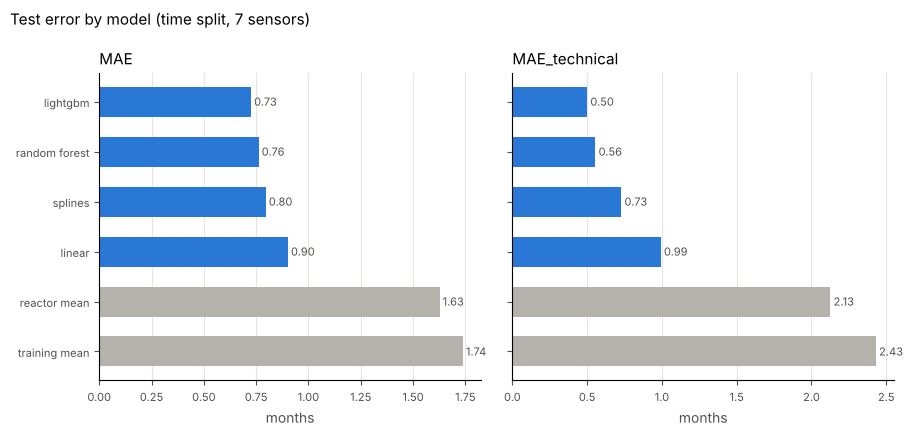

In [7]:
plots.metric_panels(main, ["MAE", "MAE_technical"], "Test error by model (time split, 7 sensors)",
                    reference=["reactor mean", "training mean"], filename="model_candidates_mae.png");

In [8]:
pd.DataFrame({
    "MAE, 7 sensors": cand.loc[("7 sensors", "time split"), "MAE"],
    "MAE, without density": cand.loc[("without density", "time split"), "MAE"],
    "MAE, random split": cand.loc[("7 sensors", "random split"), "MAE"],
}).sort_values("MAE, 7 sensors").round(3)

,"MAE, 7 sensors","MAE, without density","MAE, random split"
lightgbm,0.725,0.728,0.740
random forest,0.762,0.761,0.776
splines,0.796,0.797,0.795
linear,0.901,0.901,0.884
reactor mean,1.626,1.626,1.624
training mean,1.738,1.738,1.691


### Are the differences between the best models real?
Paired comparison on the same 59,472 test batches: mean of (|error of LightGBM| − |error of the other model|), with 95% CI. Negative = LightGBM is better.

In [9]:
y_test = y[ts["test"]]
best = test_preds[("7 sensors", "lightgbm")]
low_mask = (y_test < model.LOW_THRESHOLD).to_numpy()
pd.DataFrame({
    other: pd.concat([model.paired_error_difference(y_test, best, test_preds[("7 sensors", other)]).add_prefix("all_"),
                      model.paired_error_difference(y_test[low_mask], best[low_mask], test_preds[("7 sensors", other)][low_mask]).add_prefix("technical_")])
    for other in ["random forest", "splines", "linear"]
}).T.round(3)

,all_diff,all_ci_low,all_ci_high,technical_diff,technical_ci_low,technical_ci_high
random forest,-0.036,-0.039,-0.034,-0.055,-0.058,-0.052
splines,-0.070,-0.073,-0.068,-0.228,-0.234,-0.222
linear,-0.176,-0.181,-0.171,-0.492,-0.503,-0.481


## 4.2 · Conclusions
- **Every model beats the baselines by far:** the best halves the error of the reactor mean (MAE 0.73 vs 1.63 months) and explains ~80% of the variation (R² 0.80 vs 0.13).
- **Ranking on the test period** (MAE overall / on Technical batches): LightGBM 0.73 / 0.50, random forest 0.76 / 0.56, splines 0.80 / 0.73, linear 0.90 / 0.99.
- **The differences are real, not noise.** Paired on the same test batches, LightGBM's error is lower than the random forest's by 0.036 months (95% CI 0.034–0.039), than the splines' by 0.070, and than the linear model's by 0.18. On Technical batches the gaps are larger (0.055, 0.23 and 0.49): the flexible models capture the torque floor and the event much better.
- **Density is not needed:** without it, MAE changes by at most 0.003 months for every model. The prediction can therefore be made **before the separation step**, which is earlier and more useful.
- **No sign of optimism in the time split:** the random split is not better (LightGBM 0.74 vs 0.73), consistent with consecutive batches being practically independent (phase 2).
- **Applying the selection rule** (within 0.05 months of the best overall and 0.10 on Technical batches): the splines (+0.070) and linear models are out; the random forest (+0.036 / +0.055) is inside both margins. Which of the two tree ensembles is "simpler" was not fixed in the protocol: that choice is made, and justified, in 4.3.

## 4.3 · Robustness, error analysis and selection
Before choosing, six checks:
- **a.** which feature set to keep (with or without density);
- **b.** walk-forward validation: is the ranking stable over time?
- **c.** a stress test: what happens when something new occurs?
- **d.** Technical-batch detection, i.e. the classification metrics;
- **e.** where the errors are;
- **f.** whether plant or reactor should be inputs.

The selection rule fixed in advance uses MAE on the test period; these checks are extra evidence, and they do not change the rule after the fact.

### 4.3a · Feature set
In 4.2, removing density changed MAE by at most 0.003 months for every model. Without density, the prediction can be made **before the separation step** (earlier, more useful) and uses one input fewer. By the same simplicity logic as the selection rule, everything below uses the 6 sensors **without density**.

In [10]:
F = model.FEATURES_NO_DENSITY
event_all = (data["reactor"].isin(["Plant-04/R03", "Plant-04/R07", "Plant-04/R08"]) & (data["event_time"] >= "2023-05-08"))

def fit_predict(split, names=None):
    """Fit every candidate (or `names`) on the split's train rows; return test predictions."""
    preds = {}
    for name, est in model.make_candidates().items():
        if names is None or name in names:
            est.fit(data.loc[split["train"], F], y[split["train"]])
            preds[name] = est.predict(data.loc[split["test"], F])
    return preds

y_test = y[ts["test"]]
preds = {name: test_preds[("without density", name)] for name in ["linear", "splines", "random forest", "lightgbm"]}
print(f"test batches: {len(y_test):,}")

test batches: 59,472


### 4.3b · Walk-forward validation
Three more "train on the past, test on the next 10 days" rounds, all **inside the training period**, so the final test period stays untouched: test windows starting May 10, May 20 and May 30. The first fold is special: its training data contains only 2 days of the May 8 event.

In [11]:
folds = model.walk_forward_splits(data, ["2023-05-10", "2023-05-20", "2023-05-30"], test_days=10)
wf_rows = {}
for i, fold in enumerate(folds):
    fold_preds = fit_predict(fold)
    for name, pred in fold_preds.items():
        wf_rows[(name, f"fold {i + 1}")] = model.regression_metrics(y[fold["test"]], pred)
walk = pd.DataFrame(wf_rows).T
walk_mae = walk["MAE"].unstack(); walk_tech = walk["MAE_technical"].unstack()
walk_mae["final test"] = cand.loc[("without density", "time split"), "MAE"].reindex(walk_mae.index)
walk_tech["final test"] = cand.loc[("without density", "time split"), "MAE_technical"].reindex(walk_tech.index)
pd.concat({"MAE": walk_mae, "MAE on Technical": walk_tech}, axis=1).sort_values(("MAE", "final test")).round(3)

MAE                          MAE on Technical                         
              fold 1 fold 2 fold 3 final test           fold 1 fold 2 fold 3 final test
lightgbm       0.743  0.730  0.724      0.728            0.530  0.504  0.494      0.503
random forest  0.796  0.766  0.759      0.761            0.644  0.560  0.548      0.555
splines        0.806  0.802  0.795      0.797            0.742  0.740  0.729      0.730
linear         0.950  0.922  0.907      0.901            1.157  1.065  1.016      0.993

The walk-forward table as a picture: the ranking of the models is the same in every period.

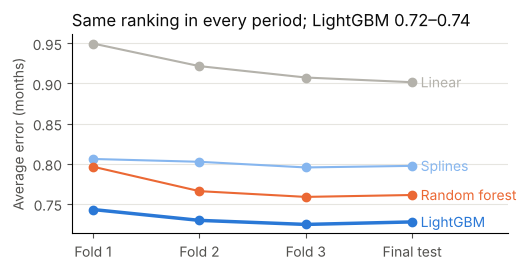

In [12]:
order = ["linear", "splines", "random forest", "lightgbm"]
lines = walk_mae.loc[order, ["fold 1", "fold 2", "fold 3", "final test"]]
lines.index = ["Linear", "Splines", "Random forest", "LightGBM"]
lines.columns = ["Fold 1", "Fold 2", "Fold 3", "Final test"]
lo, hi = lines.loc["LightGBM"].min(), lines.loc["LightGBM"].max()
plots.model_lines(lines, f"Same ranking in every period; LightGBM {lo:.2f}–{hi:.2f}", "Average error (months)",
                  highlight="LightGBM", filename="model_walk_forward.png");

In [13]:
gap = pd.DataFrame({"random forest − lightgbm, MAE": walk_mae.loc["random forest"] - walk_mae.loc["lightgbm"],
                    "random forest − lightgbm, MAE on Technical": walk_tech.loc["random forest"] - walk_tech.loc["lightgbm"]})
gap["inside margins (0.05 / 0.10)?"] = (gap.iloc[:, 0] <= 0.05) & (gap.iloc[:, 1] <= 0.10)
gap.round(3)

,"random forest − lightgbm, MAE","random forest − lightgbm, MAE on Technical",inside margins (0.05 / 0.10)?
fold 1,0.053,0.114,False
fold 2,0.036,0.056,True
fold 3,0.034,0.054,True
final test,0.034,0.052,True


### 4.3c · Stress test: a regime the model has never seen
Train only on batches **before May 8**, test on the same final test period. The model has never seen the event's low torque. How wrong is it on the event batches, and in which direction? (Bias > 0 means it predicts too high a stability, i.e. too optimistic.)

In [14]:
before_event = {"train": data["event_time"] < pd.Timestamp("2023-05-08"), "test": ts["test"]}
stress_preds = fit_predict(before_event)
ev = event_all[ts["test"]].to_numpy()
stress = {}
for name in stress_preds:
    e_unseen = stress_preds[name] - y_test.to_numpy()
    e_seen = preds[name] - y_test.to_numpy()
    stress[name] = {"event MAE, never seen": np.abs(e_unseen[ev]).mean(), "event bias, never seen": e_unseen[ev].mean(),
                    "event MAE, seen in training": np.abs(e_seen[ev]).mean(),
                    "other batches MAE, never seen": np.abs(e_unseen[~ev]).mean()}
pd.DataFrame(stress).T.round(3)

,"event MAE, never seen","event bias, never seen","event MAE, seen in training","other batches MAE, never seen"
linear,2.327,-1.865,1.458,0.832
splines,1.328,1.185,0.859,0.793
random forest,1.330,1.308,0.400,0.805
lightgbm,1.170,1.142,0.395,0.761


### 4.3d · Detecting Technical batches (classification metrics)
The model predicts a number, but the business decision is yes/no: **"is this batch Technical grade (< 20 months)?"**. Flagging a batch when its prediction is below 20 gives a classifier, with:
- **recall:** of the truly Technical batches, the share the model flags;
- **precision:** of the flagged batches, the share that really are Technical;
- **F1:** the harmonic mean of the two;
- **accuracy:** the share of correct yes/no decisions;
- **ROC-AUC and PR-AUC:** how well the predicted stability *ranks* batches by risk, at every possible threshold, not just 20.

In [15]:
detection = pd.DataFrame({name: model.technical_detection(y_test, pred) for name, pred in preds.items()}).T
detection = detection.sort_values("F1", ascending=False)
detection[["TP", "FP", "FN", "TN"]] = detection[["TP", "FP", "FN", "TN"]].astype(int)
print(f"share of test batches truly Technical: {detection['share_truly_technical'].iloc[0]:.1%} "
      f"-> a model that never flags anything already has {1 - detection['share_truly_technical'].iloc[0]:.1%} accuracy")
detection.drop(columns="share_truly_technical").round(3)

share of test batches truly Technical: 29.4% -> a model that never flags anything already has 70.6% accuracy


,TP,FP,FN,TN,accuracy,precision,recall,F1,ROC_AUC,PR_AUC
lightgbm,12654,2143,4810,39865,0.883,0.855,0.725,0.784,0.947,0.901
random forest,12148,1973,5316,40035,0.877,0.860,0.696,0.769,0.942,0.891
splines,11825,1714,5639,40294,0.876,0.873,0.677,0.763,0.946,0.894
linear,10621,1003,6843,41005,0.868,0.914,0.608,0.730,0.943,0.893


**Choosing the flag threshold is a business decision.** Flagging at "predicted < 20" misses some Technical batches, because predictions are pulled towards the average (see 4.3e). Flagging at a slightly higher predicted value catches more of them, at the cost of more false alarms. For LightGBM:

In [16]:
thresholds = {f"flag if prediction < {t}": model.technical_detection(y_test, preds["lightgbm"] - (t - 20.0))
              for t in [19.5, 20.0, 20.5, 21.0]}
pd.DataFrame(thresholds).T[["recall", "precision", "F1", "TP", "FP", "FN"]].astype({"TP": int, "FP": int, "FN": int}).round(3)

,recall,precision,F1,TP,FP,FN
flag if prediction < 19.5,0.513,0.968,0.670,8955,299,8509
flag if prediction < 20.0,0.725,0.855,0.784,12654,2143,4810
flag if prediction < 20.5,0.869,0.728,0.792,15182,5680,2282
flag if prediction < 21.0,0.951,0.617,0.748,16610,10316,854


The trade-off as a picture: moving the threshold up catches more Technical batches, at the price of more false alarms.

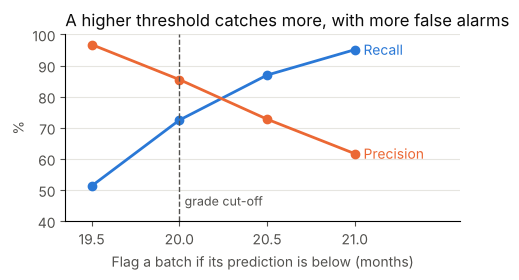

In [17]:
trade = pd.DataFrame(thresholds).T[["recall", "precision"]]
trade.index = [19.5, 20.0, 20.5, 21.0]
plots.threshold_lines(trade, "A higher threshold catches more, with more false alarms",
                      "Flag a batch if its prediction is below (months)", reference=20.0,
                      filename="model_threshold_tradeoff.png");

### 4.3e · Where are the errors?
MAE and bias (prediction − truth; + = too optimistic) for the two best models, by plant, by event vs other batches, by number of missing sensors, by true grade, and by week of the test period.

In [18]:
g = data.loc[ts["test"]]
groupings = {
    "plant": g["plant_location"],
    "May 8 event": pd.Series(np.where(event_all[ts["test"]], "event batches", "other batches"), index=g.index),
    "missing sensors": g[F].isna().sum(axis=1).clip(upper=2).map({0: "0", 1: "1", 2: "2 or more"}),
    "true grade": pd.cut(y_test, [0, 20, 25, 40], labels=["Technical (<20)", "Industrial (20-25)", "Perfumery (>=25)"]),
    "week": g["event_time"].dt.to_period("W").dt.start_time.dt.date.astype(str),
}
error_tables = {}
for gname, groups in groupings.items():
    error_tables[gname] = pd.concat({m: model.mae_by_group(y_test, preds[m], groups) for m in ["lightgbm", "random forest"]}, axis=1)
pd.concat(error_tables, names=["grouping", "group"]).round(3)

lightgbm               random forest              
                                        MAE   bias      n           MAE   bias      n
grouping        group                                                                
plant           Plant-01              0.796 -0.024  16246         0.833 -0.060  16246
                Plant-02              0.736  0.004   8126         0.774  0.044   8126
                Plant-03              0.727  0.018  11242         0.763  0.049  11242
                Plant-04              0.613  0.070  12720         0.639  0.080  12720
                Plant-05              0.754 -0.012  11138         0.785 -0.018  11138
May 8 event     event batches         0.395  0.210   5109         0.400  0.235   5109
                other batches         0.759 -0.008  54363         0.795 -0.008  54363
missing sensors 0                     0.640 -0.001  38339         0.672 -0.043  38339
                1                     0.852  0.018  17412         0.887  0.082  17412
                2 or more             1.050  0.084   3721         1.095  0.266   3721
true grade      Technical (<20)       0.503  0.384  17464         0.555  0.463  17464
                Industrial (20-25)    0.783 -0.050  38133         0.795 -0.060  38133
                Perfumery (>=25)      1.194 -1.085   3875         1.354 -1.300   3875
week            2023-06-05            0.723  0.006   8463         0.760  0.012   8463
                2023-06-12            0.727  0.015  19834         0.762  0.020  19834
                2023-06-19            0.733  0.011  19702         0.764  0.012  19702
                2023-06-26            0.724  0.004  11473         0.755  0.001  11473

The LightGBM errors as a picture: worse with missing sensors and for the rare Perfumery batches, similar across plants.

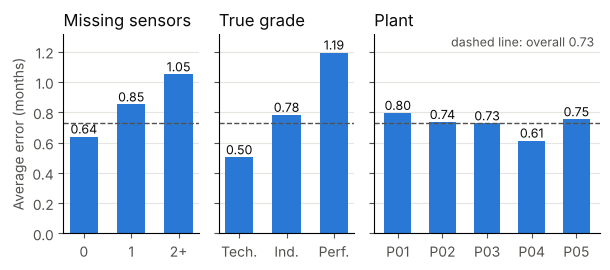

In [19]:
lgbm = {g: error_tables[g][("lightgbm", "MAE")] for g in ["missing sensors", "true grade", "plant"]}
panels = {"Missing sensors": lgbm["missing sensors"].rename({"2 or more": "2+"}),
          "True grade": lgbm["true grade"].rename({"Technical (<20)": "Tech.", "Industrial (20-25)": "Ind.", "Perfumery (>=25)": "Perf."}),
          "Plant": lgbm["plant"].rename(lambda p: p.replace("Plant-", "P"))}
overall = model.regression_metrics(y_test, preds["lightgbm"])["MAE"]
plots.group_error_panels(panels, overall, "Average error (months)", filename="model_errors_by_group.png");

### 4.3f · Should plant or reactor be inputs?
Phase 3 showed plants do not differ at equal operating conditions. Adding the reactor to LightGBM as a category:

In [20]:
import lightgbm as lgb

X_r = data[F].assign(reactor=data["reactor"].astype("category"))
with_reactor = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                                 random_state=model.SEED, verbose=-1).fit(X_r[ts["train"]], y[ts["train"]])
pd.DataFrame({"6 sensors": model.regression_metrics(y_test, preds["lightgbm"]),
              "6 sensors + reactor": model.regression_metrics(y_test, with_reactor.predict(X_r[ts["test"]]))}).T.round(3)

,MAE,MAE_technical,RMSE,R2,n
6 sensors,0.728,0.503,0.942,0.796,59472.0
6 sensors + reactor,0.721,0.483,0.922,0.805,59472.0


### 4.3g · Sanity check: would another model family do better?
*Added after the protocol, for completeness.* Other standard choices, on the same time split and the same 6 sensors: Extra Trees (a more randomised forest), scikit-learn's histogram gradient boosting, XGBoost, CatBoost and a small neural network (MLP with two hidden layers of 64 and 32 units). Plus LightGBM with a small tuning grid (tuned on the calibration window, never on the test set) and an average of three boosters. Run by `scripts/benchmark_other_models.py`, which needs `xgboost` and `catboost`; the notebook only reads its results.

In [21]:
extra = pd.read_csv(config.ROOT / "reports" / "model_benchmark_extra.csv", index_col=0)
extra[["MAE", "MAE_technical", "R2", "fit_seconds"]].round(3)

,MAE,MAE_technical,R2,fit_seconds
"average of lightgbm, xgboost, catboost",0.726,0.507,0.798,NaN
"lightgbm tuned (leaves=31, min_child=50, lr=0.02)",0.727,0.503,0.797,NaN
lightgbm (selected candidate),0.728,0.503,0.796,146.461
sklearn hist gradient boosting,0.728,0.506,0.797,2.084
xgboost,0.728,0.505,0.796,6.121
catboost,0.731,0.528,0.797,6.559
neural network (MLP 64-32),0.732,0.525,0.797,51.713
extra trees,0.774,0.610,0.773,8.829


Every flexible model, whatever its family, lands on the same error: MAE 0.726–0.732 months, R² ≈ 0.80. Tuning LightGBM gains 0.001 and averaging three boosters 0.002. The forests (random forest, Extra Trees) are slightly worse. When very different methods converge on the same number, the limit is not the algorithm but the data: about 0.73 months of error is what the 6 sensors cannot explain (measurement noise in the lab result, unmeasured factors). A different model will not change it; better or additional measurements could.

### 4.3h · Selection
**Applying the rule fixed in advance** (simplest model within 0.05 months of the best MAE and within 0.10 on Technical batches, on the final test period, 6 sensors):
- best: **LightGBM**, MAE 0.728, Technical 0.503;
- **random forest**: +0.034 / +0.052, inside both margins on the final test;
- splines (+0.070) and linear (+0.173) are outside.

The rule leaves two candidates, and the protocol did not say which tree ensemble is "simpler". The robustness checks give data-based tie-breakers, all pointing the same way:
1. **Walk-forward:** LightGBM is best in all three folds. In fold 1 (only 2 days of the event in training) the random forest falls **outside** both margins (+0.053 and +0.114), so its eligibility depends on the period.
2. **Technical detection:** LightGBM has the highest recall (72.5% vs 69.6%), F1, ROC-AUC and PR-AUC.
3. **Fewer parts:** LightGBM handles missing values itself (no imputation step), trains ~10× faster and gives a smaller model.
4. **Same explainability:** SHAP works identically for both.

**Proposed model: LightGBM on the 6 sensors without density, no plant or reactor input.**

## 4.3 · Conclusions
- **Stable over time:** LightGBM's MAE is 0.72–0.74 months in every walk-forward fold and on the final test; the ranking of the four models never changes. Error does not grow over the four test weeks (0.72–0.73): no drift within the data.
- **A new regime is the real risk.** Trained only before May 8, every model gets the event batches wrong: LightGBM's MAE on them is 1.17 months instead of 0.40, and its bias is **+1.14 months, too optimistic**. Tree models cannot predict beyond the torque they have seen; the linear model extrapolates too far the other way (−1.87). A model only knows the conditions it has seen: **monitoring (the control charts of phase 3) and regular retraining are part of the solution, not optional.**
- **Detecting Technical batches:** flagging "prediction < 20" catches **72.5%** of Technical batches (recall), and 85.5% of the flagged batches really are Technical (precision); ROC-AUC 0.947, PR-AUC 0.90. **Accuracy is misleading here** (88%): a model that never flags anything already scores 70.6%. The flag threshold is a business choice: at "prediction < 20.5" recall rises to 87% and precision falls to 73% (F1 0.79). The prediction intervals of 4.4 give a more principled flag.
- **Predictions are pulled towards the average:** Technical batches are predicted 0.38 months too high on average, Perfumery batches 1.09 months too low. That is normal for a model that cannot explain everything (R² 0.80), and it is why the flag threshold matters.
- **Missing sensors cost accuracy:** MAE 0.64 with all 6 sensors, 0.85 with one missing, 1.05 with two or more. The intervals in 4.4 should be wider for those batches.
- **No plant is badly predicted** (MAE 0.61–0.80, bias within ±0.07).
- **Reactor as an input:** it improves MAE by only 0.007 (0.721 vs 0.728) and works by memorising that three reactors had the event. If the plant fixes them, such a model would keep predicting them low, so it is not used, consistent with phase 3.

## 4.4 · Prediction intervals and an out-of-distribution flag
A prediction of "19.4 months" is not enough: the statement asks for the model's **confidence**. The goal is an interval like "19.4 months, 90% interval 18.0–20.9" that contains the true lab value for about 90% of batches, for every kind of batch.

**Split conformal prediction**, the idea in one paragraph: fit the model on the fitting period (April 1 – May 29), then look at its errors on batches it has *not* seen, the calibration period (May 30 – June 8). If 90% of those errors are smaller than *q*, then "prediction ± *q*" will cover about 90% of future batches, as long as they behave like the calibration batches. No assumption about the shape of the errors is needed.

**The final model** is now fitted on the fitting period only, so the calibration batches stay unseen. Its accuracy is the same as in 4.3.

In [22]:
fit_m, cal_m, test_m = ts["fit"], ts["calib"], ts["test"]
point_model = model.make_candidates()["lightgbm"].fit(data.loc[fit_m, F], y[fit_m])
pred_cal, pred_test = point_model.predict(data.loc[cal_m, F]), point_model.predict(data.loc[test_m, F])
print(model.regression_metrics(y_test, pred_test).round(3).to_dict())

{'MAE': 0.728, 'MAE_technical': 0.506, 'RMSE': 0.943, 'R2': 0.796, 'n': 59472.0}


### 4.4a · Three ways to build the interval
- **plain:** prediction ± *q*, with *q* the conformal 90% quantile of the absolute calibration errors: the same width for every batch;
- **per missing count:** the same, but a separate *q* for batches with 0, 1 and 2+ missing sensors (4.3 showed errors grow with missing sensors);
- **CQR** (conformalized quantile regression): two extra LightGBM models predict a low (5%) and a high (95%) value from the sensors, and a conformal correction adjusts them to 90%. The width adapts to each batch automatically.

In [23]:
missing_cal = data.loc[cal_m, F].isna().sum(axis=1).clip(upper=2)
missing_test = data.loc[test_m, F].isna().sum(axis=1).clip(upper=2)
abs_err_cal = np.abs(y[cal_m].to_numpy() - pred_cal)

q_plain = model.conformal_quantile(abs_err_cal)
q_group = {k: model.conformal_quantile(abs_err_cal[missing_cal.to_numpy() == k]) for k in [0, 1, 2]}
q_test = missing_test.map(q_group).to_numpy()
cqr = model.ConformalQuantileInterval().fit(data.loc[fit_m, F], y[fit_m], data.loc[cal_m, F], y[cal_m])
low_cqr, high_cqr = cqr.predict_interval(data.loc[test_m, F])

intervals = {
    "plain": (pred_test - q_plain, pred_test + q_plain),
    "per missing count": (pred_test - q_test, pred_test + q_test),
    "CQR": (low_cqr, high_cqr),
}
print(f"plain q = ±{q_plain:.2f} months; per missing count q = " + ", ".join(f"{k}: ±{v:.2f}" for k, v in q_group.items()))
grade_test = pd.cut(y_test, [0, 20, 25, 40], labels=["Technical", "Industrial", "Perfumery"])
missing_label = missing_test.map({0: "0 missing", 1: "1 missing", 2: "2+ missing"})
rows = {}
for name, (lo, hi) in intervals.items():
    row = model.interval_coverage(y_test, lo, hi).iloc[0].to_dict()
    row.update({f"coverage, {g}": v for g, v in model.interval_coverage(y_test, lo, hi, missing_label)["coverage"].items()})
    row.update({f"coverage, {g}": v for g, v in model.interval_coverage(y_test, lo, hi, grade_test)["coverage"].items()})
    rows[name] = row
coverage_table = pd.DataFrame(rows).T
coverage_table.round(3)

plain q = ±1.48 months; per missing count q = 0: ±1.32, 1: ±1.81, 2: ±2.34


,coverage,width,"coverage, 0 missing","coverage, 1 missing","coverage, 2+ missing","coverage, Technical","coverage, Industrial","coverage, Perfumery"
plain,0.899,2.958,0.945,0.831,0.740,0.950,0.896,0.701
per missing count,0.901,3.059,0.902,0.899,0.905,0.969,0.892,0.689
CQR,0.900,2.688,0.904,0.894,0.891,0.885,0.915,0.826


In [24]:
model.interval_coverage(y_test, low_cqr, high_cqr, missing_label).round(3)

,coverage,width,n
0 missing,0.904,2.310,38339
1 missing,0.894,3.209,17412
2+ missing,0.891,4.143,3721


Coverage per group for the three methods: plain conformal is far off for batches with missing sensors; CQR stays close to 90% for every missing-sensor group.

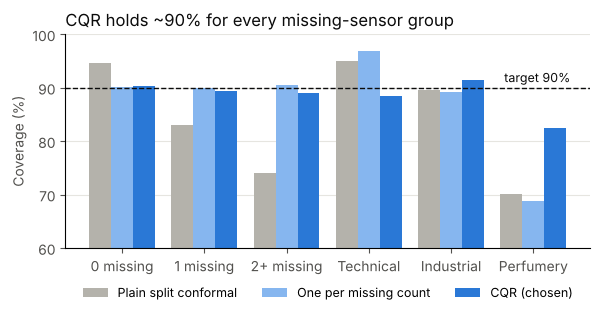

In [25]:
groups = ["0 missing", "1 missing", "2+ missing", "Technical", "Industrial", "Perfumery"]
cov = coverage_table[[f"coverage, {g}" for g in groups]] * 100
cov.columns = groups
cov.index = ["Plain split conformal", "One per missing count", "CQR (chosen)"]
plots.grouped_bars(cov, "CQR holds ~90% for every missing-sensor group", "Coverage (%)", reference=90, ylim=(60, 100),
                   filename="model_interval_coverage.png");

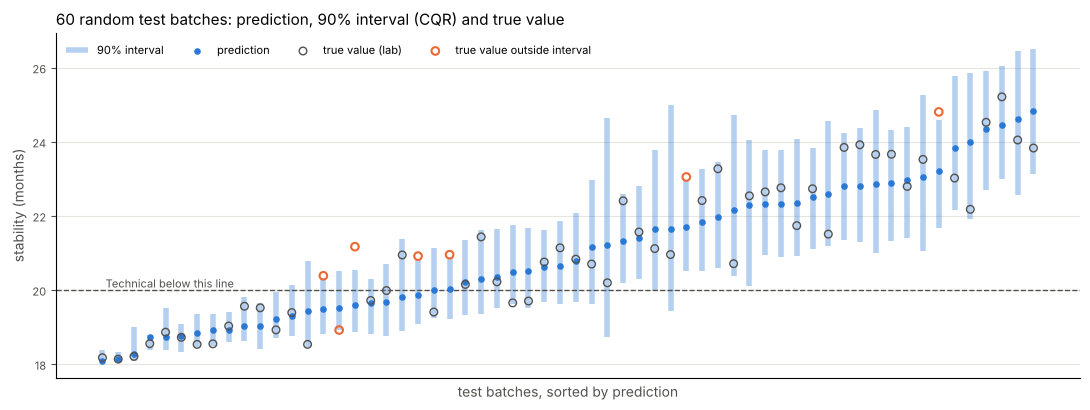

In [26]:
rng = np.random.default_rng(model.SEED)
sample = rng.choice(len(y_test), 60, replace=False)
plots.interval_examples(pred_test[sample], low_cqr[sample], high_cqr[sample], y_test.to_numpy()[sample], 20.0,
                        "60 random test batches: prediction, 90% interval (CQR) and true value",
                        filename="model_interval_examples.png");

### 4.4b · From interval to decision: a traffic light
- **red:** even the top of the interval is below 20 months, so almost surely Technical;
- **green:** even the bottom is at or above 20, so almost surely Industrial or better;
- **amber:** the interval straddles 20, so uncertain: worth a lab check.

How many batches fall in each tier, and how many of them are truly Technical?

In [27]:
tier = pd.Series(model.risk_tier(low_cqr, high_cqr), index=y_test.index, name="tier")
truly_tech = (y_test < 20)
tiers = pd.DataFrame({"batches": tier.value_counts(), "share of batches": tier.value_counts(normalize=True),
                      "truly Technical in tier": truly_tech.groupby(tier).mean(),
                      "share of all Technical batches": truly_tech.groupby(tier).sum() / truly_tech.sum()}).reindex(["red", "amber", "green"])
tiers.style.format({"batches": "{:,.0f}", "share of batches": "{:.1%}", "truly Technical in tier": "{:.1%}",
                    "share of all Technical batches": "{:.1%}"})

,batches,share of batches,truly Technical in tier,share of all Technical batches
tier,,,,
red,"6,926",11.6%,99.6%,39.5%
amber,"25,036",42.1%,41.6%,59.7%
green,"27,510",46.3%,0.5%,0.8%


The tiers as a picture: share of batches in each tier, and how many of them are truly Technical.

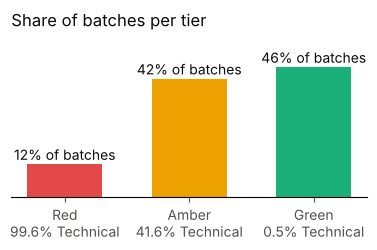

In [28]:
plots.tier_bars(tiers["share of batches"], tiers["truly Technical in tier"], "Share of batches per tier",
                filename="model_traffic_light.png");

### 4.4c · Out-of-distribution flag: Isolation Forest vs a range check
The stress test of 4.3c showed that a model trained before May 8 was confidently wrong on the event batches. A flag should say "this batch is unlike anything the model has seen". Two candidates, both fitted on the model's training data:
- **Isolation Forest:** unsupervised anomaly detection on the combination of the 6 sensors; flag the 1% most isolated scores of the training data and above;
- **range check:** flag a batch if any sensor is outside the range seen in training (0.1%–99.9%).

The real test is the stress scenario: train both on batches before May 8, and see whether they flag the event batches in the test period.

In [29]:
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

def isolation_flag(train_mask, X_new):
    iso = make_pipeline(SimpleImputer(strategy="median"), IsolationForest(n_estimators=200, random_state=model.SEED, n_jobs=-1))
    iso.fit(data.loc[train_mask, F])
    threshold = np.quantile(-iso.score_samples(data.loc[train_mask, F]), 0.99)
    return -iso.score_samples(X_new) > threshold

X_test = data.loc[test_m, F]
pre_event = data["event_time"] < pd.Timestamp("2023-05-08")
flags = {
    ("stress: trained before May 8", "isolation forest"): isolation_flag(pre_event, X_test),
    ("stress: trained before May 8", "range check"): model.RangeFlag().fit(data.loc[pre_event, F]).flag(X_test),
    ("normal: trained on the full training period", "isolation forest"): isolation_flag(ts["train"], X_test),
    ("normal: trained on the full training period", "range check"): model.RangeFlag().fit(data.loc[ts["train"], F]).flag(X_test),
}
errors = {"stress: trained before May 8": np.abs(stress_preds["lightgbm"] - y_test.to_numpy()),   # model that never saw the event
          "normal: trained on the full training period": np.abs(pred_test - y_test.to_numpy())}  # the final model
pd.DataFrame({k: {"flagged, event batches": f[ev].mean(), "flagged, other batches": f[~ev].mean(),
                  "precision for event batches": ev[f].mean() if f.any() else np.nan,
                  "model MAE, flagged": errors[k[0]][f].mean() if f.any() else np.nan,
                  "model MAE, not flagged": errors[k[0]][~f].mean()}
              for k, f in flags.items()}).T.round(3)

flagged, event batches  flagged, other batches  precision for event batches  model MAE, flagged  model MAE, not flagged
stress: trained before May 8                isolation forest                   0.080                   0.011                        0.399               0.595                   0.799
                                            range check                        0.907                   0.012                        0.879               0.999                   0.776
normal: trained on the full training period isolation forest                   0.207                   0.001                        0.949               0.155                   0.739
                                            range check                        0.041                   0.010                        0.286               0.539                   0.731

## 4.4 · Conclusions
- **The final model** (LightGBM, 6 sensors, fitted on April 1 – May 29) keeps its accuracy: MAE 0.73 months on the test period.
- **All three interval methods reach the promised 90% overall** (89.9–90.1%), but only CQR is honest for every kind of batch:
  - *plain* (± 1.48 months for everyone) covers 94.5% of batches with all sensors but only 74% of those with two or more missing;
  - *per missing count* fixes that (90.2 / 89.9 / 90.7%) with wider intervals on average (3.06);
  - **CQR** covers 90.4 / 89.4 / 89.1% and is the **narrowest on average (2.69 months)**, because it widens only where needed: 2.3 months with all sensors, 3.2 with one missing, 4.1 with two or more.
- **One honest limit:** coverage is 88.5% for Technical batches, 91.5% for Industrial, but 82.6% for Perfumery batches (≥ 25 months), the ones the model predicts too low (4.3e). That error is on the *safe side*: an excellent batch underestimated, not a bad batch shipped.
- **Chosen interval method: CQR.**
- **The traffic light turns intervals into decisions** (test period):
  - **red** (11.6% of batches): 99.6% are truly Technical. They can be downgraded without waiting for the lab; they hold 40% of all Technical batches.
  - **green** (46.3%): only 0.5% are Technical. They can be released with very low risk; only 0.8% of all Technical batches end up here.
  - **amber** (42.1%): 42% are Technical. They are the uncertain ones, and they hold 60% of all Technical batches: **these are the batches to send to the lab first**.
  So the lab can focus on 42% of production and still see 99% of the Technical batches (red + amber).
- **The out-of-distribution flag: the simple range check beats the Isolation Forest.** With models trained before May 8 (the stress case), the range check flags **91%** of the event batches with 1.2% false alarms (precision 88%), and flagged batches have a clearly higher model error (1.00 vs 0.78 months). The Isolation Forest flags only 8% of them: the event is extreme in **one** sensor (torque), and the Isolation Forest's random splits spread over all six sensors, which dilutes it. With the final model (which has seen the event), the range check flags 1% of batches.
- **Chosen flag: the range check**, shown next to every prediction as "conditions outside what the model has seen: trust the prediction less and check in the lab".

## 4.5 · The final package: prediction, interval, traffic light, flag and explanation
Everything the Quality team gets for a batch, in one object (`model.StabilityPredictor`):
- the **prediction** in months (LightGBM, 6 sensors);
- the **90% interval** (CQR);
- the **traffic light** (red / amber / green);
- the **out-of-range flag**;
- an **explanation**: how much each sensor pushed this batch up or down (SHAP).

It is fitted on April 1 – May 29 and calibrated on May 30 – June 8, as in 4.4. Batches without any sensor data (excluded so far) get their reactor's training average with a wider interval, so **every** batch gets an answer.

In [30]:
predictor = model.StabilityPredictor().fit(df[df["event_time"] < model.CALIB_START],
                                          df[(df["event_time"] >= model.CALIB_START) & (df["event_time"] < model.TRAIN_END)])
test_all = df[df["event_time"] >= model.TRAIN_END]          # includes the batches without sensor data
result = predictor.predict_frame(test_all)
y_all = test_all[config.TARGET]
summary = {}
for name, mask in {"batches with sensor data": ~result["no_sensor_data"], "batches without sensor data": result["no_sensor_data"],
                   "all test batches": pd.Series(True, index=result.index)}.items():
    r, yy = result[mask], y_all[mask]
    summary[name] = {"batches": int(mask.sum()), "MAE": (r["prediction"] - yy).abs().mean(),
                     "coverage of 90% interval": ((yy >= r["low"]) & (yy <= r["high"])).mean(),
                     "mean width": (r["high"] - r["low"]).mean(), "share amber": (r["tier"] == "amber").mean()}
pd.DataFrame(summary).T.round(3)

,batches,MAE,coverage of 90% interval,mean width,share amber
batches with sensor data,59472.0,0.728,0.900,2.688,0.421
batches without sensor data,1258.0,1.659,0.908,5.923,1.000
all test batches,60730.0,0.748,0.900,2.755,0.433


### 4.5a · Global explanation: what drives the predictions
Mean absolute SHAP value per sensor on 10,000 test batches: the average size of each sensor's contribution, in months. The shape of each effect is the one already shown in 03 §3.3d, where a model of the same kind was fitted for the root-cause cross-check.

mixing_torque_nm                0.403
reaction_temperature_celsius    0.205
ph_level                        0.173
vessel_pressure_bar             0.119
refractive_index                0.065
mass_flow_rate_kg_h             0.036
Name: share of total, dtype: float64

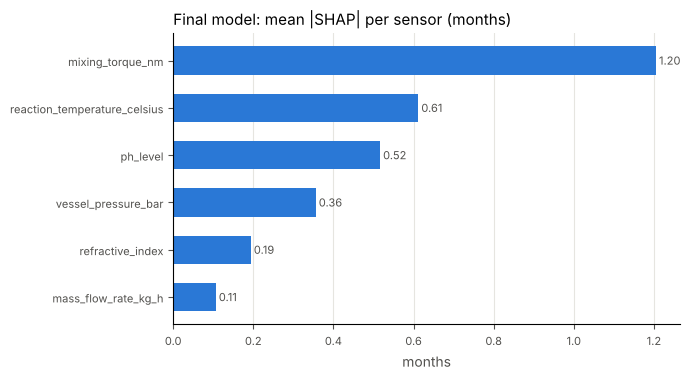

In [31]:
import shap

sample_idx = test_all[~result["no_sensor_data"]].sample(10_000, random_state=model.SEED).index
contrib_sample = predictor.explain(test_all.loc[sample_idx])
global_imp = contrib_sample[F].abs().mean().sort_values(ascending=False)
plots.importance_bars(global_imp, "Final model: mean |SHAP| per sensor (months)", "months",
                      filename="model_shap_importance.png")
(global_imp / global_imp.sum()).round(3).rename("share of total")

### 4.5b · Explaining single batches
One example of each case the Quality team will see: a red, an amber and a green batch, a batch whose conditions are out of range, and a batch without sensor data. For each, the prediction, its interval and tier, and the plain-language explanation.

In [32]:
rng = np.random.default_rng(7)
def pick(mask):
    idx = result.index[mask]
    return idx[rng.integers(len(idx))]

with_data = ~result["no_sensor_data"]
examples = {
    "red": pick(with_data & (result["tier"] == "red") & ~result["out_of_range"]),
    "amber": pick(with_data & (result["tier"] == "amber") & ~result["out_of_range"]),
    "green": pick(with_data & (result["tier"] == "green") & ~result["out_of_range"]),
    "out of range": pick(result["out_of_range"]),
    "no sensor data": pick(result["no_sensor_data"]),
}
ex_rows = test_all.loc[list(examples.values())]
ex_contrib = predictor.explain(ex_rows)
for case, idx in examples.items():
    text = predictor.explain_text(test_all.loc[idx], result.loc[idx], ex_contrib.loc[idx])
    print(f"[{case}] {test_all.loc[idx, 'batch_id']} ({test_all.loc[idx, 'reactor']}), lab result {y_all[idx]:.1f} months")
    print("   " + text + "\n")

[red] BATCH-2023-245525 (Plant-04/R08), lab result 18.4 months
   Predicted 18.3 months (90% interval 18.2–18.5), tier red. Main reasons vs the average batch (21.6): mixing torque 10.69 N·m (-2.8 months); temperature 91.21 °C (-0.7 months); pH 5.45 (+0.4 months).

[amber] BATCH-2023-162789 (Plant-01/R09), lab result 19.8 months
   Predicted 21.1 months (90% interval 19.9–22.2), tier amber. Main reasons vs the average batch (21.6): mixing torque 11.70 N·m (-1.3 months); temperature 82.32 °C (+0.7 months); pressure 2.58 bar (-0.7 months).

[green] BATCH-2023-177105 (Plant-02/R03), lab result 23.4 months
   Predicted 24.0 months (90% interval 22.4–25.5), tier green. Main reasons vs the average batch (21.6): mixing torque 12.46 N·m (+2.3 months); temperature 90.38 °C (-1.1 months); pressure 2.35 bar (+0.5 months).

[out of range] BATCH-2023-229599 (Plant-01/R04), lab result 20.9 months
   Predicted 21.2 months (90% interval 20.0–22.7), tier green. Main reasons vs the average batch (21.6): 

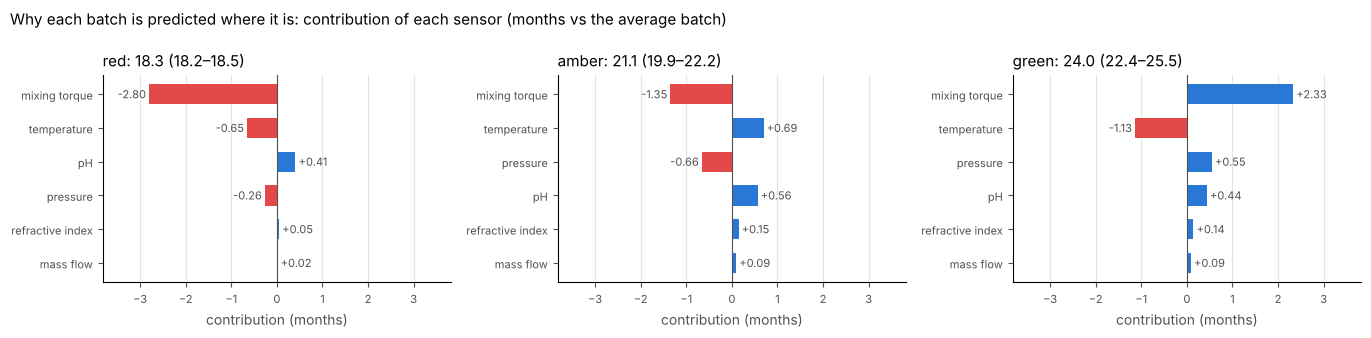

In [33]:
panels = {f"{case}: {result.loc[idx, 'prediction']:.1f} ({result.loc[idx, 'low']:.1f}–{result.loc[idx, 'high']:.1f})":
          ex_contrib.loc[idx, F].rename(index=model.LABELS)
          for case, idx in list(examples.items())[:3]}
plots.contribution_panels(panels, "Why each batch is predicted where it is: contribution of each sensor (months vs the average batch)",
                          filename="model_batch_explanations.png");

### 4.5c · Save and reload
The fitted package is saved to `models/stability_predictor.joblib` (not committed: it is regenerated by running this notebook) and reloaded to check it gives identical results.

In [34]:
predictor.save(config.MODEL_PATH)
reloaded = model.StabilityPredictor.load(config.MODEL_PATH)
same = np.allclose(reloaded.predict_frame(test_all.head(1000))[["prediction", "low", "high"]],
                   result.head(1000)[["prediction", "low", "high"]])
print(f"saved to {config.MODEL_PATH.relative_to(config.ROOT)}; reloaded predictions identical: {same}")

saved to models/stability_predictor.joblib; reloaded predictions identical: True


## 4.5 · Conclusions
- **Every test batch gets an answer.** For the 59,472 batches with sensor data: MAE 0.73 months, 90.0% interval coverage, mean width 2.7 months. For the 1,258 without sensor data: the reactor's usual level, MAE 1.66, coverage 90.8%, width 5.9 months, and always amber, i.e. "check in the lab", which is the right answer when nothing is known. Overall: MAE 0.75, coverage 90.0%.
- **What drives the predictions** (share of the mean |SHAP|): torque 40%, temperature 21%, pH 17%, pressure 12%, refractive index 7%, mass flow 4%. The same ranking as the root cause analysis of phase 3: the model has learned the process, not an artefact.
- **Each prediction comes with its reasons, in months.** For example:
  - *red*, Plant-04/R08: 18.3 months (18.2–18.5), because torque is 10.7 N·m (−2.8 months) and the temperature 91 °C (−0.7); the lab measured 18.4;
  - *green*, Plant-02/R03: 24.0 months (22.4–25.5), torque 12.5 N·m (+2.3) outweighs a hot reaction (−1.1); the lab measured 23.4.
  The explanation adds up exactly: average batch (21.6) + contributions = prediction.
- **The package is saved** (`models/stability_predictor.joblib`) and reloads with identical results. How to use it, what it can and cannot do: `docs/model_card.md`.